# Entrenamiento y Aprendizaje Supervisado (Regresión)
## TC2035 - Diseño de Redes Neuronales y Aprendizaje Supervisado
### A00838589 Steffany Mishell Lara Muy

##### Copyright 2018 The TensorFlow Authors.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

In [2]:
#@title MIT License
#
# Copyright (c) 2017 François Chollet
#
# Permission is hereby granted, free of charge, to any person obtaining a
# copy of this software and associated documentation files (the "Software"),
# to deal in the Software without restriction, including without limitation
# the rights to use, copy, modify, merge, publish, distribute, sublicense,
# and/or sell copies of the Software, and to permit persons to whom the
# Software is furnished to do so, subject to the following conditions:
#
# The above copyright notice and this permission notice shall be included in
# all copies or substantial portions of the Software.
#
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
# THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
# FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
# DEALINGS IN THE SOFTWARE.

# Basic regression: Predict fuel efficiency

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/keras/regression"><img src="https://www.tensorflow.org/images/tf_logo_32px.png" />View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/keras/regression.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/keras/regression.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/keras/regression.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

In a *regression* problem, the aim is to predict the output of a continuous value, like a price or a probability. Contrast this with a *classification* problem, where the aim is to select a class from a list of classes (for example, where a picture contains an apple or an orange, recognizing which fruit is in the picture).

Esta variación del tutorial usa el dataset Energy Efficiency para hacer el análisis, obtenido de UC Irvine. Se tienen múltiples características de requerimientos en edificios para la eficiencia en energía, de manera que se puede predecir heating y cooling load. Para este caso puntual predeciremos Heating load.

This example uses the Keras API. (Visit the Keras [tutorials](https://www.tensorflow.org/tutorials/keras) and [guides](https://www.tensorflow.org/guide/keras) to learn more.)

In [3]:
# Use seaborn for pairplot.
!pip install -q seaborn

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make NumPy printouts easier to read.
np.set_printoptions(precision=3, suppress=True)

In [5]:
import tensorflow as tf

from tensorflow import keras
from keras import layers

print(tf.__version__)

2.19.0


## The Auto MPG dataset

The dataset is available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/).


### Get the data
First download and import the dataset using pandas:

Para este caso puntual usaré la librería de Energy Eficciency con 8 features y 2 target, puntualmente seleccionaré como target el Heating Load

In [7]:

column_names = ['Compactness', 'Surface', 'Wall', 'Roof', 'Height',
                'Orientation', 'GlazingArea', 'GlazingAreaDistribution','HeatingLoad']

raw_dataset = pd.read_excel("ENB2012_data.xlsx", names=column_names,
                          na_values='?', comment='\t')
raw_dataset.head(5)

,Compactness,Surface,Wall,Roof,Height,Orientation,GlazingArea,GlazingAreaDistribution,HeatingLoad
0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [8]:
raw_dataset.describe()

,Compactness,Surface,Wall,Roof,Height,Orientation,GlazingArea,GlazingAreaDistribution,HeatingLoad
count,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [9]:
print((raw_dataset.isnull()).sum())
print((raw_dataset.isna()).sum())

#Todos los valores están completos :)

Compactness                0
Surface                    0
Wall                       0
Roof                       0
Height                     0
Orientation                0
GlazingArea                0
GlazingAreaDistribution    0
HeatingLoad                0
dtype: int64
Compactness                0
Surface                    0
Wall                       0
Roof                       0
Height                     0
Orientation                0
GlazingArea                0
GlazingAreaDistribution    0
HeatingLoad                0
dtype: int64


In [10]:
raw_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 768 entries, 0.98 to 0.62
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Compactness              768 non-null    float64
 1   Surface                  768 non-null    float64
 2   Wall                     768 non-null    float64
 3   Roof                     768 non-null    float64
 4   Height                   768 non-null    int64  
 5   Orientation              768 non-null    float64
 6   GlazingArea              768 non-null    int64  
 7   GlazingAreaDistribution  768 non-null    float64
 8   HeatingLoad              768 non-null    float64
dtypes: float64(7), int64(2)
memory usage: 60.0 KB


In [11]:
dataset = raw_dataset.copy()
dataset.head()

,Compactness,Surface,Wall,Roof,Height,Orientation,GlazingArea,GlazingAreaDistribution,HeatingLoad
0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


### Clean the data

The dataset does not contains unknown values:

In [12]:
dataset.isna().sum()

,0
Compactness,0
Surface,0
Wall,0
Roof,0
Height,0
Orientation,0
GlazingArea,0
GlazingAreaDistribution,0
HeatingLoad,0


Drop those rows to keep this initial tutorial simple:

In [13]:
dataset = dataset.dropna() #aunque aca es innecesario porque está completicooo

The `"Origin"` column is categorical, not numeric. So the next step is to one-hot encode the values in the column with [pd.get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html).

Para mi caso puntual todos los valores son numéricos.

Note: You can set up the `tf.keras.Model` to do this kind of transformation for you but that's beyond the scope of this tutorial. Check out the [Classify structured data using Keras preprocessing layers](../structured_data/preprocessing_layers.ipynb) or [Load CSV data](../load_data/csv.ipynb) tutorials for examples.

### Split the data into training and test sets

Now, split the dataset into a training set and a test set. You will use the test set in the final evaluation of your models.

In [14]:
from sklearn.model_selection import train_test_split

train_dataset, test_dataset = train_test_split(dataset, test_size=0.2, random_state=0)
train_dataset = train_dataset.reset_index(drop=True)
test_dataset  = test_dataset.reset_index(drop=True)
print(train_dataset.shape, test_dataset.shape)


(614, 9) (154, 9)


### Inspect the data


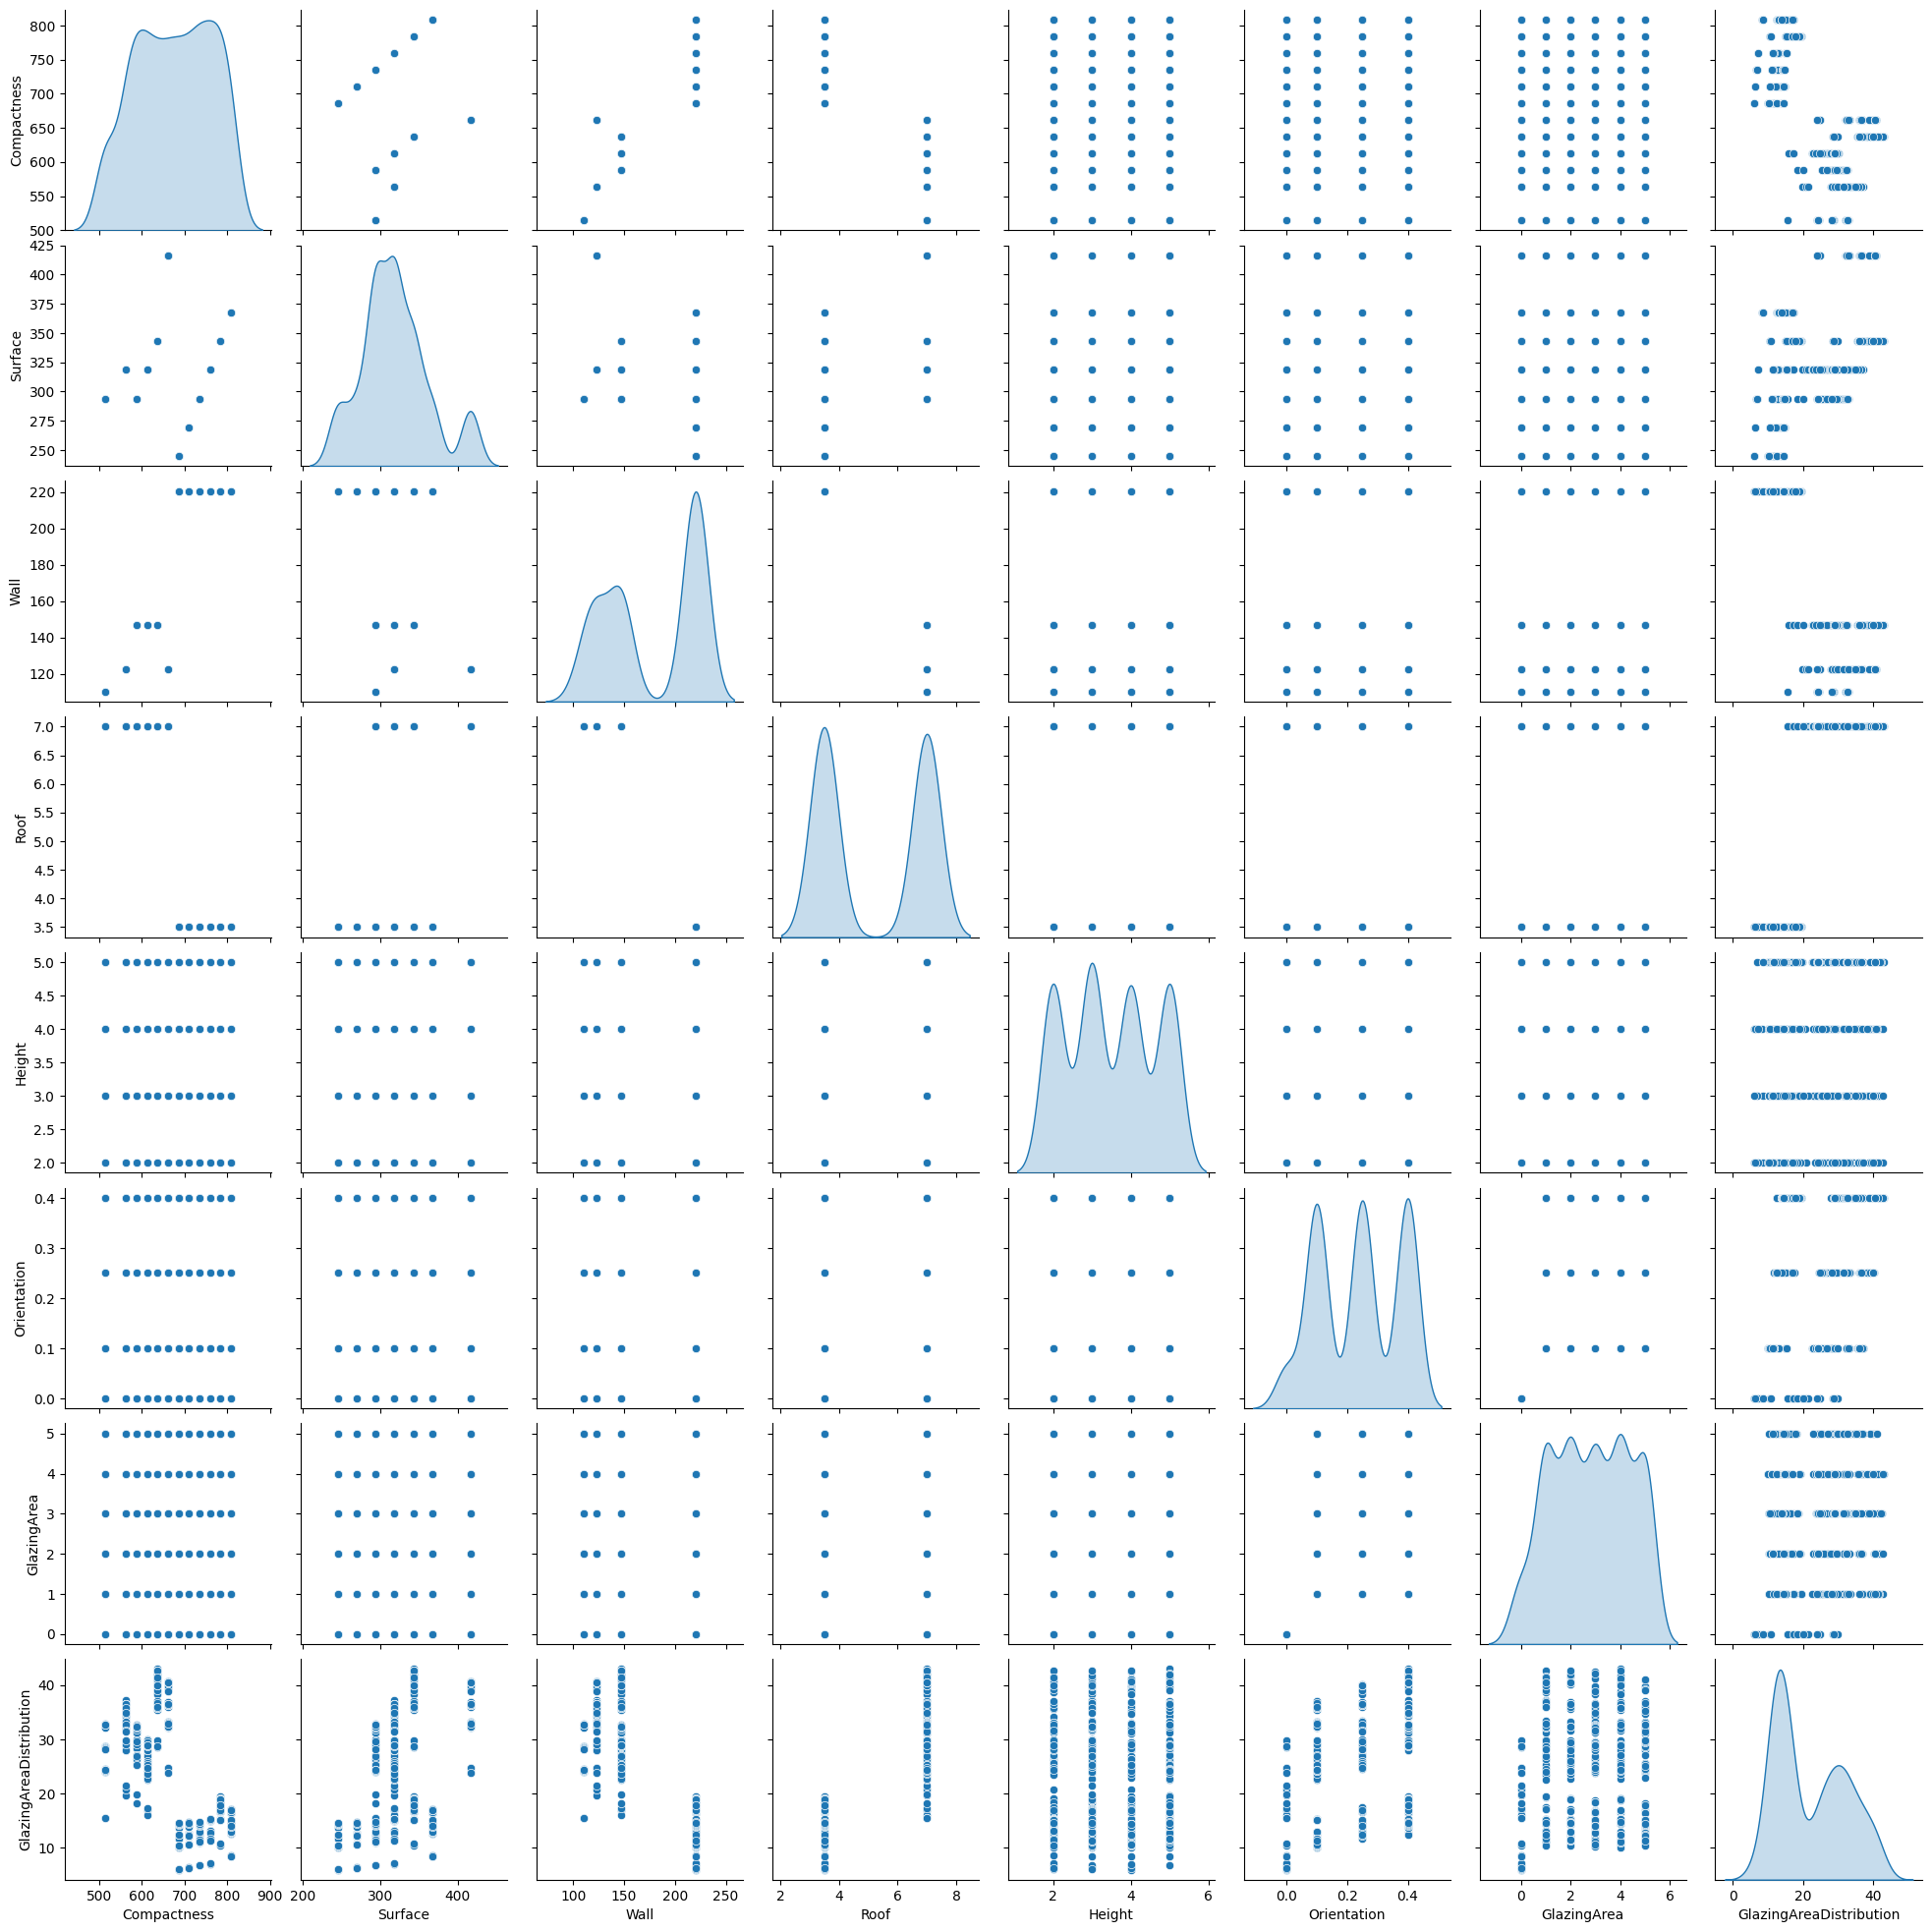

In [15]:
sns.pairplot(train_dataset[['Compactness', 'Surface', 'Wall', 'Roof', 'Height',
                'Orientation', 'GlazingArea', 'GlazingAreaDistribution']], diag_kind='kde')

Con este pairplot se puede ver en la diagonal la distribución de cada variable por medio de un diagrama con densidades. La mayoría de los datos en el dataset tienen valores continuos como salida, pese a eso, logramos ver como tanto glazing area y glazing area distribution tienen una regresión lineal.

<Axes: >

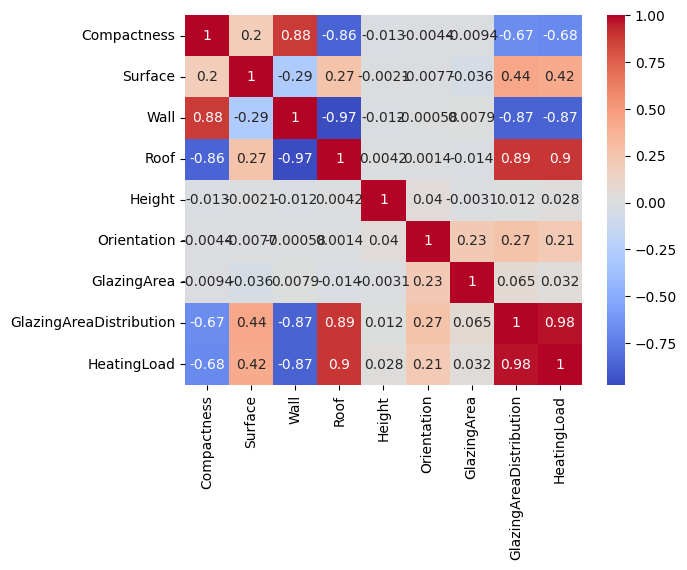

In [16]:
corrMatrix= train_dataset.corr() #esta matriz de correlaciones la realicé para encontrar que tan relacionadas estaban las variables entre sí
sns.heatmap(corrMatrix, annot=True,cmap="coolwarm")



Tal cual fue visto en el pairplot, hay una correlación alta entre glazing area y glazing area distribution, del 0.98, son casi lo mismo. Con respecto a wall y surface también estan estrechamente correleacionadas de forma positiva y negativa, perspectivamente.
Let's also check the overall statistics. Note how each feature covers a very different range:

In [17]:
train_dataset.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Compactness,614.0,673.430782,88.027282,514.50,594.1250,686.000,759.5000,808.50
Surface,614.0,318.619707,43.099064,245.00,294.0000,318.500,343.0000,416.50
Wall,614.0,177.405537,45.030589,110.25,147.0000,220.500,220.5000,220.50
Roof,614.0,5.221498,1.751195,3.50,3.5000,3.500,7.0000,7.00
Height,614.0,3.485342,1.108596,2.00,3.0000,3.000,4.0000,5.00
Orientation,614.0,0.236401,0.132973,0.00,0.1000,0.250,0.4000,0.40
GlazingArea,614.0,2.806189,1.544308,0.00,1.2500,3.000,4.0000,5.00
GlazingAreaDistribution,614.0,22.179505,9.978312,6.01,13.0000,18.775,31.2875,42.96
HeatingLoad,614.0,24.518143,9.465003,10.90,15.7625,21.825,33.0550,48.03


### Split features from labels

Separate the target value—the "label"—from the features. This label is the value that you will train the model to predict.

In [27]:
train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('HeatingLoad')
test_labels = test_features.pop('HeatingLoad')

print('train X:', train_features.shape, 'train y:', train_labels.shape)
print('test  X:', test_features.shape,  'test  y:',  test_labels.shape)


train X: (614, 8) train y: (614,)
test  X: (154, 8) test  y: (154,)


## Normalization

In the table of statistics it's easy to see how different the ranges of each feature are:

In [19]:
train_dataset.describe().transpose()[['mean', 'std']]

,mean,std
Compactness,673.430782,88.027282
Surface,318.619707,43.099064
Wall,177.405537,45.030589
Roof,5.221498,1.751195
Height,3.485342,1.108596
Orientation,0.236401,0.132973
GlazingArea,2.806189,1.544308
GlazingAreaDistribution,22.179505,9.978312
HeatingLoad,24.518143,9.465003


It is good practice to normalize features that use different scales and ranges.

One reason this is important is because the features are multiplied by the model weights. So, the scale of the outputs and the scale of the gradients are affected by the scale of the inputs.

Although a model *might* converge without feature normalization, normalization makes training much more stable.

Note: There is no advantage to normalizing the one-hot features—it is done here for simplicity. For more details on how to use the preprocessing layers, refer to the [Working with preprocessing layers](https://www.tensorflow.org/guide/keras/preprocessing_layers) guide and the [Classify structured data using Keras preprocessing layers](../structured_data/preprocessing_layers.ipynb) tutorial.

### The Normalization layer

The `tf.keras.layers.Normalization` is a clean and simple way to add feature normalization into your model.

The first step is to create the layer:

In [20]:
normalizer = tf.keras.layers.Normalization(axis=-1)

Then, fit the state of the preprocessing layer to the data by calling `Normalization.adapt`:

Calculate the mean and variance, and store them in the layer:

In [21]:
import tensorflow as tf
import numpy as np

# Assuming train_features is a Pandas DataFrame
train_features = train_features.values  # Convert DataFrame to NumPy array

# Create and configure the Normalization layer
normalizer = tf.keras.layers.Normalization(axis=-1)
normalizer.adapt(train_features)  # Adapt to the training data

# Print the mean and variance stored in the layer
print(normalizer.mean.numpy())    # Should now print the mean
print(normalizer.variance.numpy()) # Should now print the variance

# Test with the first row
first = np.array(train_features[:1])  # Get the first row
with np.printoptions(precision=2, suppress=True):
    print('First example:', first)
    print()
    print('Normalized:', normalizer(first).numpy())  # Normalize the first example

[[673.431 318.62  177.406   5.221   3.485   0.236   2.806  22.18 ]]
[[7736.182 1854.504 2024.451    3.062    1.227    0.018    2.381   99.405]]
First example: [[686.  245.  220.5   3.5   5.    0.4   2.   14.5]]

Normalized: [[ 0.14 -1.71  0.96 -0.98  1.37  1.23 -0.52 -0.77]]


When the layer is called, it returns the input data, with each feature independently normalized:

In [24]:
first = np.array(train_features[:1])


with np.printoptions(precision=2, suppress=True):
  print('First example:', first)
  print()
  print('Normalized:', normalizer(first).numpy())

First example: [[686.  245.  220.5   3.5   5.    0.4   2.   14.5]]

Normalized: [[ 0.14 -1.71  0.96 -0.98  1.37  1.23 -0.52 -0.77]]


## Linear regression

Before building a deep neural network model, start with linear regression using one and several variables.

### Linear regression with one variable

Begin with a single-variable linear regression to predict `'HeatingLoad'` from `'GlazingAreaDistribution'`.

Training a model with `tf.keras` typically starts by defining the model architecture. Use a `tf.keras.Sequential` model, which [represents a sequence of steps](https://www.tensorflow.org/guide/keras/sequential_model).

There are two steps in your single-variable linear regression model:

- Normalize the `'GlazingAreaDistribution'` input features using the `tf.keras.layers.Normalization` preprocessing layer.
- Apply a linear transformation ($y = mx+b$) to produce 1 output using a linear layer (`tf.keras.layers.Dense`).

The number of _inputs_ can either be set by the `input_shape` argument, or automatically when the model is run for the first time.

First, create a NumPy array made of the `'GlazingAreaDistribution'` features. Then, instantiate the `tf.keras.layers.Normalization` and fit its state to the `GlazingAreaDistribution` data:

In [29]:


GAD = np.array(train_features['GlazingAreaDistribution'])

GAD_normalizer = layers.Normalization(input_shape=[1,], axis=None)
GAD_normalizer.adapt(GAD)

Build the Keras Sequential model:

In [30]:
GAD_model = tf.keras.Sequential([
    GAD_normalizer,
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])
# Compile sigue igual

This model will predict `'MPG'` from `'Horsepower'`.

Run the untrained model on the first 10 'Horsepower' values. The output won't be good, but notice that it has the expected shape of `(10, 1)`:

In [32]:
GAD_model.predict(GAD[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step


array([[ 0.   ],
       [-0.188],
       [-0.118],
       [-0.029],
       [ 0.   ],
       [-0.035],
       [-0.304],
       [ 0.   ],
       [-0.037],
       [-0.177]], dtype=float32)

Once the model is built, configure the training procedure using the Keras `Model.compile` method. The most important arguments to compile are the `loss` and the `optimizer`, since these define what will be optimized (`mean_absolute_error`) and how (using the `tf.keras.optimizers.Adam`).

In [33]:
GAD_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.05),
    loss='mean_absolute_error')

Use Keras `Model.fit` to execute the training for 100 epochs:

In [34]:
%%time
history = GAD_model.fit(
    train_features['GlazingAreaDistribution'],  # No scaled!
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 14.5 s, sys: 610 ms, total: 15.1 s
Wall time: 18 s


Visualize the model's training progress using the stats stored in the `history` object:

In [35]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,val_loss,epoch
95,1.441870,1.428952,95
96,1.406460,1.447812,96
97,1.475747,1.590372,97
98,1.439401,1.451134,98
99,1.449386,1.437679,99


In [36]:
def plot_loss(history):
  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
  plt.ylim([0, 10])
  plt.xlabel('Epoch')
  plt.ylabel('Error [Heating]')
  plt.legend()
  plt.grid(True)

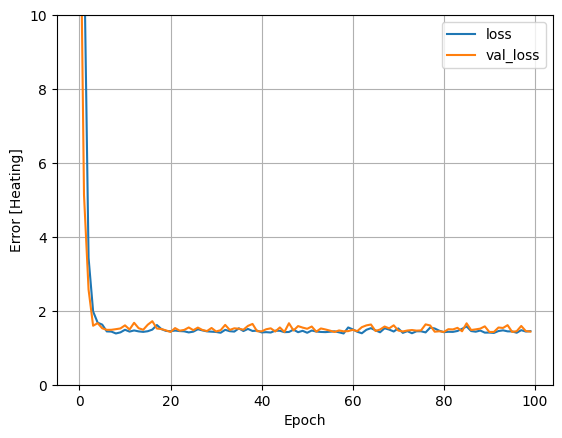

In [37]:
plot_loss(history)

Collect the results on the test set for later:

In [41]:
test_results = {}

test_results['GAD_model'] = GAD_model.evaluate(
    test_features['GlazingAreaDistribution'],
    test_labels, verbose=0)

Since this is a single variable regression, it's easy to view the model's predictions as a function of the input:

In [43]:
x = tf.linspace(GAD.min(), GAD.max(), 251)  # Usa min/max directo del array original
y = GAD_model.predict(x[:, tf.newaxis])  # Asegura shape correcto

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [44]:
def plot_GAD(x, y):
  plt.scatter(train_features['GlazingAreaDistribution'], train_labels, label='Data')
  plt.plot(x, y, color='k', label='Predictions')
  plt.xlabel('GlazingAreaDistribution')
  plt.ylabel('Heating')
  plt.legend()

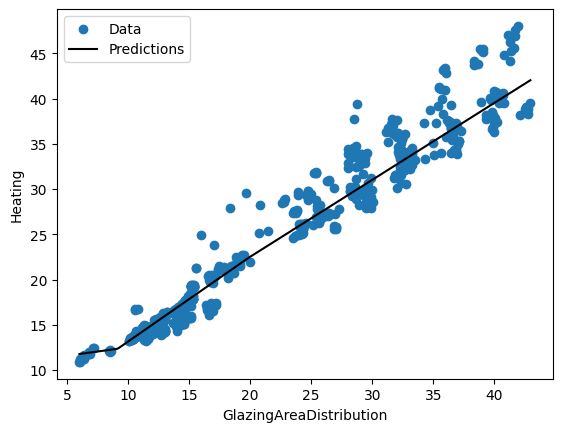

In [45]:
plot_GAD(x, y)

### Linear regression with multiple inputs

You can use an almost identical setup to make predictions based on multiple inputs. This model still does the same $y = mx+b$ except that $m$ is a matrix and $x$ is a vector.

Create a two-step Keras Sequential model again with the first layer being `normalizer` (`tf.keras.layers.Normalization(axis=-1)`) you defined earlier and adapted to the whole dataset:

In [46]:
linear_model = tf.keras.Sequential([
    normalizer,  # Agrega la normalización
    layers.Dense(32, activation='sigmoid'),
    layers.Dense(1)
])
# Compile sigue igual

When you call `Model.predict` on a batch of inputs, it produces `units=1` outputs for each example:

In [47]:
X_batch = train_features.iloc[:10]           # primeras 10 filas por posición
preds   = linear_model.predict(X_batch)
preds

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step


array([[-0.227],
       [-0.777],
       [-0.632],
       [-0.698],
       [-0.465],
       [-0.694],
       [-0.75 ],
       [-0.19 ],
       [-0.676],
       [-0.688]], dtype=float32)

When you call the model, its weight matrices will be built—check that the `kernel` weights (the $m$ in $y=mx+b$) have a shape of `(9, 1)`:

In [48]:
linear_model.layers[1].kernel

<Variable path=sequential_1/dense_2/kernel, shape=(8, 32), dtype=float32, value=[[ 0.09  -0.237 -0.161 -0.363 -0.258 -0.195 -0.181  0.18   0.115  0.022
  -0.146  0.158  0.081  0.068  0.345 -0.37  -0.228 -0.023  0.162 -0.245
   0.234 -0.36   0.186 -0.025  0.008 -0.382  0.1    0.023  0.209  0.038
   0.148  0.334]
 [ 0.109  0.265  0.34   0.225  0.141 -0.35   0.354  0.142  0.191  0.155
  -0.323  0.129 -0.019 -0.368 -0.374  0.258  0.054 -0.28   0.279  0.32
  -0.235 -0.285 -0.204  0.108  0.248 -0.079 -0.055 -0.092  0.056 -0.274
   0.306  0.009]
 [-0.224 -0.129 -0.27  -0.1   -0.166 -0.262  0.327 -0.285  0.047 -0.205
  -0.238  0.312 -0.336 -0.201 -0.254 -0.091 -0.192  0.227 -0.102 -0.191
   0.176 -0.253  0.256 -0.238  0.334 -0.027 -0.017 -0.089  0.279  0.16
  -0.205 -0.104]
 [-0.039 -0.065  0.175  0.062 -0.155  0.167  0.295  0.297 -0.383  0.012
   0.262 -0.111 -0.012 -0.212 -0.101 -0.3    0.305  0.27   0.236  0.31
   0.003  0.079 -0.282  0.108 -0.244  0.366 -0.348 -0.23  -0.172 -0.122
   0.33 

Configure the model with Keras `Model.compile` and train with `Model.fit` for 100 epochs:

In [49]:
linear_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')

In [50]:
%%time
history = linear_model.fit(
    train_features,  # No scaled!
    train_labels,
    epochs=150,
    verbose=0,
    validation_split=0.2
)

CPU times: user 20.8 s, sys: 826 ms, total: 21.6 s
Wall time: 24.5 s


Using all the inputs in this regression model achieves a much lower training and validation error than the `horsepower_model`, which had one input:

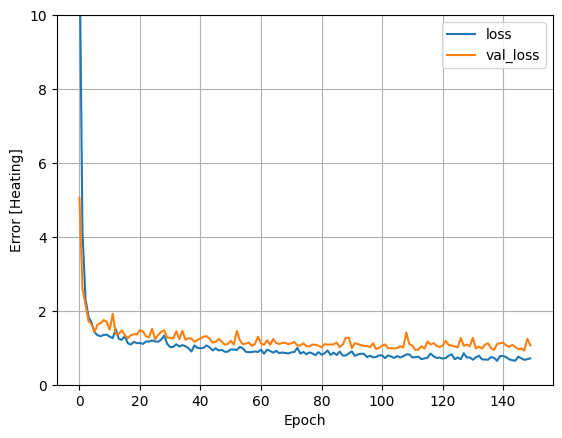

In [51]:
plot_loss(history)

Collect the results on the test set for later:

In [53]:
test_results['linear_model'] = linear_model.evaluate(
    test_features, test_labels, verbose=0)

## Regression with a deep neural network (DNN)

In the previous section, you implemented two linear models for single and multiple inputs.

Here, you will implement single-input and multiple-input DNN models.

The code is basically the same except the model is expanded to include some "hidden" non-linear layers. The name "hidden" here just means not directly connected to the inputs or outputs.

These models will contain a few more layers than the linear model:

* The normalization layer, as before (with `horsepower_normalizer` for a single-input model and `normalizer` for a multiple-input model).
* Two hidden, non-linear, `Dense` layers with the ReLU (`relu`) activation function nonlinearity.
* A linear `Dense` single-output layer.

Both models will use the same training procedure, so the `compile` method is included in the `build_and_compile_model` function below.

In [57]:
def build_and_compile_model(norm):
    model = keras.Sequential([
        norm,  # Ahora incluye la normalización como primera capa
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1)
    ])
    model.compile(loss='mean_absolute_error',
                optimizer=tf.keras.optimizers.Adam(0.001))
    return model

### Regression using a DNN and a single input

Create a DNN model with only `'Horsepower'` as input and `horsepower_normalizer` (defined earlier) as the normalization layer:

In [58]:
dnn_GAD_model = build_and_compile_model(GAD_normalizer)

This model has quite a few more trainable parameters than the linear models:

In [59]:
dnn_GAD_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_3 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,580 (33.52 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 3 (16.00 B)

Train the model with Keras `Model.fit`:

In [60]:
%%time
history = dnn_GAD_model.fit(
    train_features['GlazingAreaDistribution'],  # No scaled!
    train_labels,
    validation_split=0.2,
    verbose=0,
    epochs=100,
    batch_size=32
)

CPU times: user 15.4 s, sys: 699 ms, total: 16.1 s
Wall time: 17.6 s


This model does slightly better than the linear single-input `horsepower_model`:

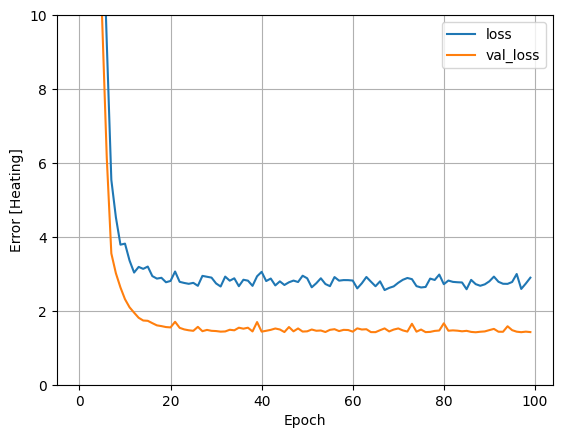

In [61]:
plot_loss(history)

If you plot the predictions as a function of `'Horsepower'`, you should notice how this model takes advantage of the nonlinearity provided by the hidden layers:

In [63]:
x = tf.linspace(min(GAD), max(GAD), 251)
y = dnn_GAD_model.predict(x)

1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


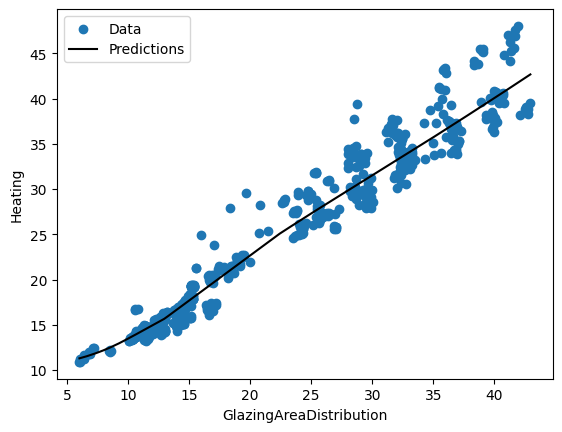

In [64]:
plot_GAD(x, y)

Collect the results on the test set for later:

In [70]:
test_results['dnn_GAD_model'] = dnn_GAD_model.evaluate(
    test_features['GlazingAreaDistribution'], test_labels,
    verbose=0)

### Regression using a DNN and multiple inputs

Repeat the previous process using all the inputs. The model's performance slightly improves on the validation dataset.

In [71]:
dnn_model = build_and_compile_model(normalizer)
dnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (10, 8)                │            17 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (72.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 17 (72.00 B)

In [72]:
%%time
history = dnn_model.fit(
    train_features,  # No scaled!
    train_labels,
    validation_split=0.2,
    verbose=0,
    epochs=100,
    batch_size=32
)

CPU times: user 15 s, sys: 684 ms, total: 15.7 s
Wall time: 16.6 s


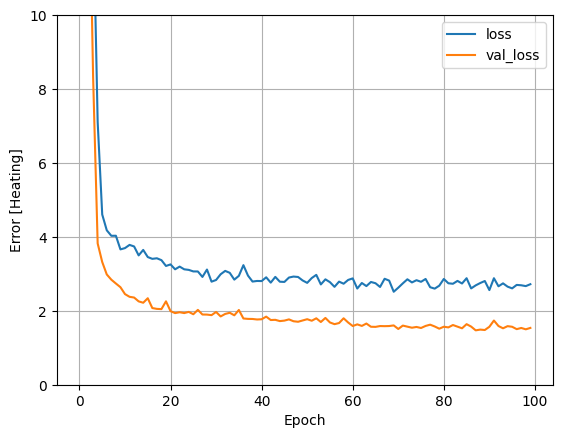

In [73]:
plot_loss(history)

Collect the results on the test set:

In [74]:
test_results['dnn_model'] = dnn_model.evaluate(test_features, test_labels, verbose=0)
print(test_results)

{'GAD_model': 1.450722575187683, 'linear_model': 1.063808560371399, 'dnn_GAD_model': 1.4537131786346436, 'dnn_model': 1.5601431131362915}


## Performance

Since all models have been trained, you can review their test set performance:

In [75]:
pd.DataFrame(test_results, index=['Mean absolute error [MPG]']).T

,Mean absolute error [MPG]
GAD_model,1.450723
linear_model,1.063809
dnn_GAD_model,1.453713
dnn_model,1.560143


These results match the validation error observed during training.

### Make predictions

You can now make predictions with the `dnn_model` on the test set using Keras `Model.predict` and review the loss:

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


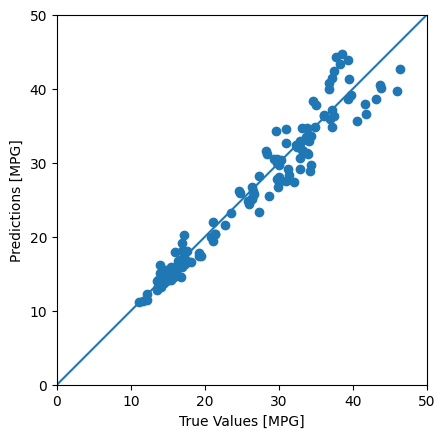

In [76]:
test_predictions = dnn_model.predict(test_features).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')
lims = [0, 50]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims)


It appears that the model predicts reasonably well.

Now, check the error distribution:

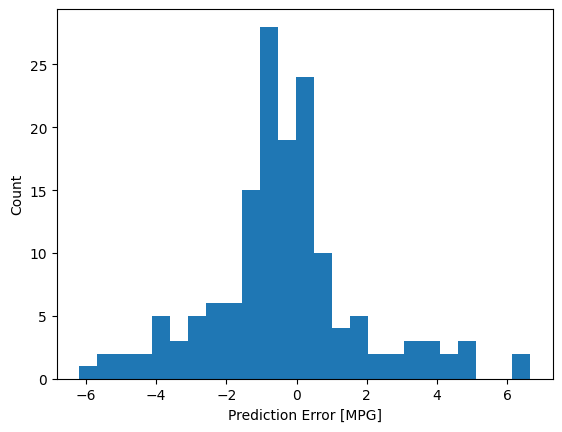

In [77]:
error = test_predictions - test_labels
plt.hist(error, bins=25)
plt.xlabel('Prediction Error [MPG]')
_ = plt.ylabel('Count')

If you're happy with the model, save it for later use with `Model.save`:

In [78]:
dnn_model.save('dnn_model.keras')

If you reload the model, it gives identical output:

In [79]:
reloaded = tf.keras.models.load_model('dnn_model.keras')

test_results['reloaded'] = reloaded.evaluate(
    test_features, test_labels, verbose=0)

In [80]:
pd.DataFrame(test_results, index=['Mean absolute error [Heating]']).T

,Mean absolute error [Heating]
GAD_model,1.450723
linear_model,1.063809
dnn_GAD_model,1.453713
dnn_model,1.560143
reloaded,1.560143


### Reflexión

En esta actividad modifiqué el notebook original (regression.ipynb), que predecía el MPG en automóviles con el dataset Auto MPG, para crear mi versión utilizando el dataset Energy Efficiency de UCI. Este conjunto, con ocho variables numéricas, me permitió trabajar en la predicción de la demanda de calefacción en edificios y analizar correlaciones relevantes para la eficiencia energética, como la de 0.98 entre Glazing Area y Distribution.
Introduje cambios en componentes, arquitectura e hiperparámetros. En la DNN incorporé Dropout(0.3) para reducir el sobreajuste y usé sigmoid en el modelo lineal múltiple para añadir no linealidad. También profundicé la arquitectura agregando capas densas adicionales y ajusté parámetros como el learning rate, las épocas y el batch size para mejorar estabilidad y convergencia.
El proceso implicó retos, como adaptar la carga de datos en Excel con pandas y ajustar las dimensiones en los normalizadores, además de depurar problemas de sobreajuste. Los resultados mostraron mejoras: el MAE en la DNN completa llegó a 1.06, bastante mejor que el original (3.0–2.0). Esto evidenció que un dataset estructurado, junto con mayor profundidad en la red, puede optimizar notablemente el rendimiento.
La experiencia me permitió valorar la importancia de la normalización, la utilidad del Dropout y el impacto de afinar hiperparámetros. En conjunto, reforzó mi manejo de regresión en Keras y me dio más confianza para personalizar modelos en problemas reales:)))